# 07 Evaluation

**IDX Exchange Data Science Internship, Week 8 deliverable** (the task document names it `06_evaluation.ipynb`; this project's notebooks are numbered one step ahead)

**Goal.** Evaluate the final model in more depth than one headline number: report R², MAE, RMSE, MAPE and MdAPE side by side for every model so far, save them as `results/metrics_summary.csv`, and find where the final model works well and where it does not (by price band, county, home size and age, and how many past sales its ZIP code has).

**The final model,** from Week 7: LightGBM (gradient-boosted trees) with the 24 Week 6 inputs, trained on 24 months of sales and predicting log price. Before evaluating it, Section 1 checks the one loose end from Week 7: its chosen setting sat at the edge of the tuning grid.

**Setup, unchanged.** Settings are chosen on the validation month, March 2026 (training on March 2024 to February 2026). The final model is trained on April 2024 to March 2026 and scored once on the test month, April 2026. Nothing in this notebook uses the test month to choose anything.

**The measures.** For a home with sale price $y$ and prediction $\hat y$, the *percentage error* is $|\hat y - y| / y$.
- **MdAPE:** the median percentage error, the headline measure (half of the homes are predicted at least this well).
- **MAPE:** the mean percentage error.
- **MAE / RMSE:** the mean absolute error and the root mean squared error, in dollars.
- **R²:** the share of the variation in sale prices that the predictions explain.
- **Within 10%:** the share of homes predicted within 10% of the sale price (also within 5% and 20%).
- **Signed error:** the median of $(\hat y - y) / y$; negative means priced too low.

**Contents**
1. Load the data; extend the Week 7 tuning grid
2. Train the final model and the earlier models
3. All measures, all models (`metrics_summary.csv`)
4. How accurate is the final model, home by home?
5. By price band
6. By county
7. By home size, age and ZIP-code sales history
8. The largest misses
9. Stability over time
10. Saved results
11. Summary and next steps

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import lightgbm as lgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

ROOT = next(p for p in [Path('..'), Path('.')] if (p / 'src' / 'preprocessing.py').exists()).resolve()
sys.path.insert(0, str(ROOT))
import src.preprocessing as prep
import src.modeling as mdl
import src.features as feat

SEED = prep.set_global_seed()
print('Random seed:', SEED, '| LightGBM', lgb.__version__)

SPLIT = json.loads((ROOT / 'config' / 'split_config.json').read_text())
W7 = json.loads((ROOT / 'config' / 'model_config_week7.json').read_text())
RESULTS_DIR = ROOT / 'results'
FIG_DIR = ROOT / 'reports' / 'figures'
TEST_MONTH = SPLIT['final']['test_month']
VALIDATION_MONTH = SPLIT['tuning']['validation_month']
NEARBY_K = int(W7['nearby_k'])
N_MONTHS = int(W7['n_train_months'])          # 24
N_MONTHS_ORIGINAL = int(SPLIT['n_train_months'])  # 12, used by the Week 4 and Week 5 models
FULL = list(W7['inputs'])
assert FULL == feat.WITH_NEARBY
GB_WEEK7 = {k: W7['lightgbm'][k] for k in ['learning_rate', 'max_depth', 'n_estimators']}
RF_SETTINGS = W7['random_forest']
RF_WEEK5 = {'n_estimators': 300, 'max_features': 0.33, 'min_samples_leaf': 1}   # chosen in 04_model_comparison

COLORS = {'Linear regression': '#2a78d6', 'Random forest': '#1baf7a', 'LightGBM': '#4a3aa7', 'Baseline': '#a3a29d',
          'Random forest (Week 5)': '#86d6b8'}
LIGHT_GRAY = '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c9c8c3', 'axes.linewidth': 0.8, 'axes.grid': True,
    'grid.color': LIGHT_GRAY, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e', 'font.size': 9.5,
})
pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')


def save_fig(name):
    plt.savefig(FIG_DIR / f'{name}.png', dpi=130, bbox_inches='tight')


def money(x, _=None):
    return f'${x / 1e6:.1f}M' if abs(x) >= 1e6 else f'${x / 1e3:.0f}K'


def pct_axis(ax, decimals=1, axis='y'):
    f = mtick.FuncFormatter(lambda v, _: f'{v:.{decimals}f}%')
    (ax.yaxis if axis == 'y' else ax.xaxis).set_major_formatter(f)


def show(df):
    out = df.copy()
    pct = ['MAPE', 'MdAPE', 'within 5%', 'within 10%', 'within 20%', 'median signed error']
    for c in out.columns:
        if c == 'R2':
            out[c] = out[c].map('{:.3f}'.format)
        elif c in ('MAE', 'RMSE'):
            out[c] = out[c].map('${:,.0f}'.format)
        elif c == 'homes':
            out[c] = out[c].map('{:,.0f}'.format)
        elif c in pct:
            out[c] = out[c].map('{:.2f}%'.format)
    return out


def lightgbm(learning_rate, max_depth, n_estimators):
    # Each tree may have up to 2^depth - 1 leaves; rows and inputs are subsampled (80%) for each tree
    return lgb.LGBMRegressor(learning_rate=learning_rate, max_depth=max_depth, num_leaves=2 ** max_depth - 1,
                             n_estimators=n_estimators, min_child_samples=20, subsample=0.8, subsample_freq=1,
                             colsample_bytree=0.8, random_state=SEED, deterministic=True, force_row_wise=True,
                             n_jobs=8, verbose=-1)


print('Week 7 LightGBM setting:', GB_WEEK7)

Random seed: 42 | LightGBM 4.7.0
Week 7 LightGBM setting: {'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 3000}


## 1. Load the data; extend the Week 7 tuning grid

Week 7 tuned LightGBM over learning rates 0.03, 0.05 and 0.1, depths 5 to 8 and 250 to 3,000 trees. The one-standard-error rule chose **learning rate 0.05, depth 8, 3,000 trees**: the deepest trees and the most trees tried. A choice at the edge of a grid may mean that larger settings would do better, so the grid is extended one step at the chosen learning rate: depths 8, 9 and 10, with up to 5,000 trees. The same rule then picks the setting with the fewest total leaves among those statistically tied with the best. Everything here uses the validation month only.

In [2]:
data = feat.add_all_features(prep.load_clean(ROOT / 'data' / 'processed' / 'sfr_clean.csv'))
train_tune, val_tune, _ = prep.make_split(data, VALIDATION_MONTH, N_MONTHS)
train_final, test_final, _ = prep.make_split(data, TEST_MONTH, N_MONTHS)
_, X_tune, X_val, ly_tune = mdl.prepare_matrices(FULL, train_tune, val_tune, nearby_k=NEARBY_K)
pre_final, X_final, X_test, ly_final = mdl.prepare_matrices(FULL, train_final, test_final, nearby_k=NEARBY_K)
y_val, y_test = val_tune[prep.TARGET].to_numpy(), test_final[prep.TARGET].to_numpy()
print(f'Settings split: {train_tune.CloseMonth.min()} to {train_tune.CloseMonth.max()} ({len(train_tune):,} sales) -> '
      f'{VALIDATION_MONTH} ({len(val_tune):,})')
print(f'Final split:    {train_final.CloseMonth.min()} to {train_final.CloseMonth.max()} ({len(train_final):,} sales) -> '
      f'{TEST_MONTH} ({len(test_final):,})')

Settings split: 2024-03 to 2026-02 (262,847 sales) -> 2026-03 (11,345)
Final split:    2024-04 to 2026-03 (262,805 sales) -> 2026-04 (12,248)


In [3]:
EXT_RATE = GB_WEEK7['learning_rate']
EXT_DEPTHS = [8, 9, 10]
EXT_COUNTS = [2000, 3000, 4000, 5000]

ext_preds, ext_complexity = {}, {}
start = time.time()
for depth in EXT_DEPTHS:
    model = lightgbm(EXT_RATE, depth, max(EXT_COUNTS)).fit(X_tune, ly_tune)
    for n in EXT_COUNTS:
        ext_preds[(EXT_RATE, depth, n)] = np.exp(model.predict(X_val, num_iteration=n))
        ext_complexity[(EXT_RATE, depth, n)] = n * (2 ** depth - 1)
print(f'{len(EXT_DEPTHS)} models, {len(ext_preds)} settings scored in {time.time() - start:.0f} s')

FINAL_KEY, ext_table = mdl.one_se_select(y_val, ext_preds, ext_complexity)
GB_FINAL = {'learning_rate': FINAL_KEY[0], 'max_depth': FINAL_KEY[1], 'n_estimators': FINAL_KEY[2]}
week7_key = (GB_WEEK7['learning_rate'], GB_WEEK7['max_depth'], GB_WEEK7['n_estimators'])
best_key = ext_table['MdAPE'].idxmin()
print('Lowest validation MdAPE:', best_key, f"{ext_table.loc[[best_key], 'MdAPE'].item():.3f}%")
print('Week 7 setting:         ', week7_key, f"{ext_table.loc[[week7_key], 'MdAPE'].item():.3f}%",
      f"(gap {ext_table.loc[[week7_key], 'gap_to_best'].item():.3f}, one SE {ext_table.loc[[week7_key], 'se_of_gap'].item():.3f})")
print('One-SE choice:          ', GB_FINAL, '(unchanged from Week 7)' if FINAL_KEY == week7_key else '(changed)')
ext_view = ext_table.copy()
ext_view.index = [f'depth {d}, {n:,} trees' for _, d, n in ext_view.index]
ext_view[['MdAPE', 'gap_to_best', 'se_of_gap', 'within_1se']].round(3)

3 models, 12 settings scored in 92 s


Lowest validation MdAPE: (0.05, 10, 3000) 6.927%
Week 7 setting:          (0.05, 8, 3000) 6.963% (gap 0.036, one SE 0.064)
One-SE choice:           {'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 3000} (unchanged from Week 7)


,MdAPE,gap_to_best,se_of_gap,within_1se
"depth 8, 2,000 trees",7.07,0.14,0.07,False
"depth 8, 3,000 trees",6.96,0.04,0.06,True
"depth 8, 4,000 trees",6.94,0.02,0.06,True
"depth 8, 5,000 trees",6.99,0.07,0.06,False
"depth 9, 2,000 trees",7.04,0.11,0.06,False
"depth 9, 3,000 trees",7.08,0.15,0.06,False
"depth 9, 4,000 trees",7.13,0.20,0.06,False
"depth 9, 5,000 trees",7.15,0.22,0.06,False
"depth 10, 2,000 trees",6.99,0.06,0.04,False
"depth 10, 3,000 trees",6.93,0.00,0.00,True


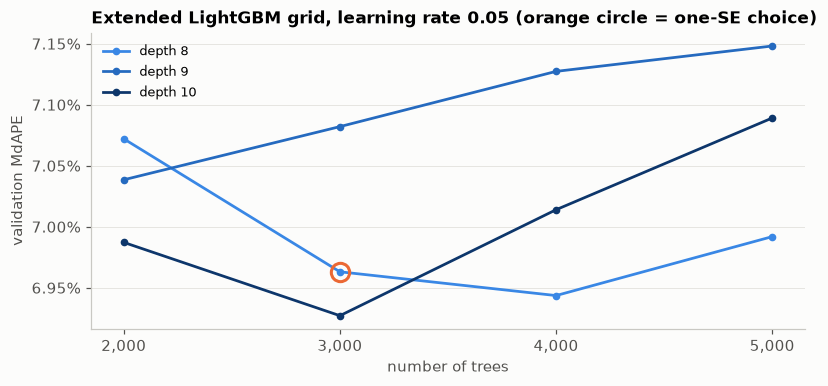

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
depth_colors = dict(zip(EXT_DEPTHS, ['#3987e5', '#256abf', '#0d366b']))
for depth in EXT_DEPTHS:
    v = [ext_table.loc[[(EXT_RATE, depth, n)], 'MdAPE'].item() for n in EXT_COUNTS]
    ax.plot(EXT_COUNTS, v, color=depth_colors[depth], lw=1.8, marker='o', ms=4, label=f'depth {depth}')
ax.plot(FINAL_KEY[2], ext_table.loc[[FINAL_KEY], 'MdAPE'].item(), marker='o', ms=12, mfc='none', mec='#eb6834', mew=2)
ax.set_xticks(EXT_COUNTS, [f'{n:,}' for n in EXT_COUNTS])
ax.set_xlabel('number of trees')
ax.set_ylabel('validation MdAPE')
pct_axis(ax, 2)
ax.grid(axis='x', visible=False)
ax.legend(frameon=False, fontsize=8.5)
ax.set_title(f'Extended LightGBM grid, learning rate {EXT_RATE} (orange circle = one-SE choice)')
plt.tight_layout()
save_fig('07_gb_extension')
plt.show()

## 2. Train the final model and the earlier models

Every model in the project so far is trained on its own training window and scored on the April 2026 test month:

| Model | Inputs | Training months |
|---|---|---|
| Week 4 baseline: linear regression | 17 original inputs | 12 (April 2025 to March 2026) |
| Week 5: random forest | 17 original inputs | 12 |
| Linear regression | 24 new inputs | 24 (April 2024 to March 2026) |
| Random forest (Week 6 best) | 24 new inputs | 24 |
| **LightGBM (final)** | **24 new inputs** | **24** |

The Week 4 and 5 models are retrained with their saved settings (rather than read from saved results) so that every measure, including RMSE and the shares within 5%, 10% and 20%, is available for all of them. The retrained scores are checked against the saved ones.

The training window also sets the outlier cutoffs, so the two windows keep slightly different test homes: 12,268 for the 12-month models and 12,248 for the 24-month models (all of which are among the 12,268). Each model's overall score uses its own test homes, as in earlier weeks; comparisons home by home use the 12,248 homes all five models share.

In [5]:
test_preds, fit_seconds = {}, {}
for name, make in [('Week 4 baseline', LinearRegression),
                   ('Random forest (Week 5)', lambda: RandomForestRegressor(**RF_WEEK5, n_jobs=-1, random_state=SEED))]:
    start = time.time()
    model, _, ev12, _ = mdl.fit_and_score(data, TEST_MONTH, N_MONTHS_ORIGINAL, make)
    fit_seconds[name] = time.time() - start
    test_preds[name] = pd.Series(model.predict(ev12[prep.input_columns(prep.FEATURES)]), index=ev12['ListingKey'].to_numpy())
y12 = pd.Series(ev12[prep.TARGET].to_numpy(), index=ev12['ListingKey'].to_numpy())

models = {
    'Linear regression': LinearRegression(),
    'Random forest': RandomForestRegressor(**RF_SETTINGS, n_jobs=-1, random_state=SEED),
    'LightGBM': lightgbm(**GB_FINAL),
}
for name, model in models.items():
    start = time.time()
    model.fit(X_final, ly_final)
    fit_seconds[name] = time.time() - start
    test_preds[name] = pd.Series(np.exp(model.predict(X_test)), index=test_final['ListingKey'].to_numpy())
final_gb = models['LightGBM']
y24 = pd.Series(y_test, index=test_final['ListingKey'].to_numpy())
print('Training time:', {k: f'{v:.0f} s' for k, v in fit_seconds.items()})

# The retrained Week 4 and Week 5 models must match their saved test scores
w4 = pd.read_csv(RESULTS_DIR / '03_baseline_metrics.csv').query('eval_month == @TEST_MONTH').iloc[0]
w5 = pd.read_csv(RESULTS_DIR / '04_model_comparison.csv').query('eval_month == @TEST_MONTH and model == "Random forest"').iloc[0]
for name, saved in [('Week 4 baseline', w4), ('Random forest (Week 5)', w5)]:
    now = prep.regression_metrics(y12, test_preds[name])
    print(f"{name}: MdAPE now {now['MdAPE']:.4f}%, saved {saved['MdAPE']:.4f}%; R2 now {now['R2']:.4f}, saved {saved['R2']:.4f}")

Training time: {'Week 4 baseline': '0 s', 'Random forest (Week 5)': '6 s', 'Linear regression': '0 s', 'Random forest': '10 s', 'LightGBM': '12 s'}
Week 4 baseline: MdAPE now 11.3780%, saved 11.3780%; R2 now 0.8198, saved 0.8198
Random forest (Week 5): MdAPE now 7.7601%, saved 7.7601%; R2 now 0.8855, saved 0.8855


## 3. All measures, all models (`metrics_summary.csv`)

In [6]:
SPEC = {
    'Week 4 baseline':        ('Week 4 baseline: linear regression', 'original (17)', N_MONTHS_ORIGINAL, y12),
    'Random forest (Week 5)': ('Week 5: random forest', 'original (17)', N_MONTHS_ORIGINAL, y12),
    'Linear regression':      ('Linear regression', 'new (24)', N_MONTHS, y24),
    'Random forest':          ('Week 6: random forest', 'new (24)', N_MONTHS, y24),
    'LightGBM':               ('Week 7/8: LightGBM (final)', 'new (24)', N_MONTHS, y24),
}
summary = pd.DataFrame([{'model': label, 'inputs': inputs, 'training months': months,
                         **mdl.full_metrics(y, test_preds[key])}
                        for key, (label, inputs, months, y) in SPEC.items()]).set_index('model')
summary = summary[['inputs', 'training months', 'homes', 'R2', 'MAE', 'RMSE', 'MAPE', 'MdAPE',
                   'within 5%', 'within 10%', 'within 20%', 'median signed error']]
show(summary)

,inputs,training months,homes,R2,MAE,RMSE,MAPE,MdAPE,within 5%,within 10%,within 20%,median signed error
model,,,,,,,,,,,,
Week 4 baseline: linear regression,original (17),12,"12,268",0.820,"$207,051","$408,669",15.17%,11.38%,23.58%,44.66%,74.48%,-1.31%
Week 5: random forest,original (17),12,"12,268",0.885,"$159,355","$325,799",11.42%,7.76%,35.12%,59.82%,83.97%,-1.47%
Linear regression,new (24),24,"12,248",0.867,"$175,061","$347,560",13.10%,9.46%,27.81%,52.02%,80.87%,-0.89%
Week 6: random forest,new (24),24,"12,248",0.900,"$148,862","$300,880",10.81%,7.40%,35.66%,61.41%,86.15%,-1.35%
Week 7/8: LightGBM (final),new (24),24,"12,248",0.920,"$136,276","$269,320",10.12%,7.00%,37.60%,64.20%,88.10%,-1.23%


**How sure are the final model's numbers?** The test homes are resampled with replacement 1,000 times and every measure is recomputed on each resample; the middle 95% of the results is the *95% range*. It shows how much each measure would move with a different draw of homes from the same month.

In [7]:
intervals = mdl.bootstrap_intervals(y24, test_preds['LightGBM'])
fmt = {'R2': '{:.3f}', 'MAE': '${:,.0f}', 'RMSE': '${:,.0f}'}
intervals_view = intervals.apply(lambda r: r.map(fmt.get(r.name, '{:.2f}%').format), axis=1)
intervals_view

,value,95% low,95% high
R2,0.920,0.913,0.927
MAPE,10.12%,9.91%,10.34%
MdAPE,7.00%,6.86%,7.13%
MAE,"$136,276","$132,039","$140,730"
RMSE,"$269,320","$255,789","$284,133"
within 10%,64.20%,63.35%,65.07%


## 4. How accurate is the final model, home by home?

The percentage errors of the final model are strongly skewed: most homes are predicted closely, and a small share is far off. That is why MAPE (the mean) is well above MdAPE (the median), and why MdAPE is the headline measure.

MdAPE 7.00%, MAPE 10.12%
The worst 1% of homes account for 8% of the total percentage error
The worst 5% of homes account for 22% of the total percentage error
The worst 10% of homes account for 35% of the total percentage error
MAPE without the worst 1% of homes: 9.45%
Homes off by more than 25%: 7.6%, more than 50%: 1.2%


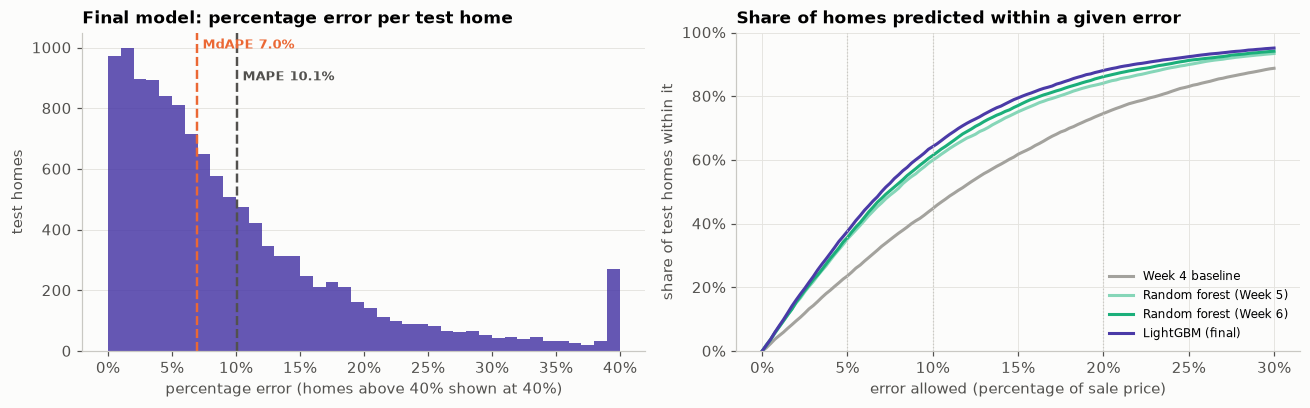

In [8]:
common = y24.index                                   # the 12,248 test homes every model scored
ape_gb = (100 * (test_preds['LightGBM'] - y24).abs() / y24).to_numpy()
order = np.sort(ape_gb)[::-1]
worst_share = {q: 100 * order[:int(round(q / 100 * len(order)))].sum() / order.sum() for q in [1, 5, 10]}
print(f'MdAPE {np.median(ape_gb):.2f}%, MAPE {ape_gb.mean():.2f}%')
for q, s in worst_share.items():
    print(f'The worst {q}% of homes account for {s:.0f}% of the total percentage error')
trim = np.sort(ape_gb)[:int(0.99 * len(ape_gb))]
print(f'MAPE without the worst 1% of homes: {trim.mean():.2f}%')
print(f'Homes off by more than 25%: {100 * np.mean(ape_gb > 25):.1f}%, more than 50%: {100 * np.mean(ape_gb > 50):.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.hist(np.clip(ape_gb, 0, 40), bins=np.arange(0, 40.5, 1), color=COLORS['LightGBM'], alpha=0.85)
top = ax.get_ylim()[1]
for v, lab, c, h in [(np.median(ape_gb), 'MdAPE', '#eb6834', 0.95), (ape_gb.mean(), 'MAPE', '#52514e', 0.85)]:
    ax.axvline(v, color=c, lw=1.6, ls='--')
    ax.text(v + 0.4, top * h, f'{lab} {v:.1f}%', color=c, fontsize=8.5, fontweight='bold')
ax.set_xlabel('percentage error (homes above 40% shown at 40%)')
ax.set_ylabel('test homes')
pct_axis(ax, 0, axis='x')
ax.set_title('Final model: percentage error per test home')
ax.grid(axis='x', visible=False)

ax = axes[1]
xs = np.linspace(0, 30, 121)
for key, label, color in [('Week 4 baseline', 'Week 4 baseline', COLORS['Baseline']),
                          ('Random forest (Week 5)', 'Random forest (Week 5)', COLORS['Random forest (Week 5)']),
                          ('Random forest', 'Random forest (Week 6)', COLORS['Random forest']),
                          ('LightGBM', 'LightGBM (final)', COLORS['LightGBM'])]:
    a = 100 * (test_preds[key].loc[common] - y24).abs() / y24
    ax.plot(xs, [100 * np.mean(a <= x) for x in xs], color=color, lw=2, label=label)
for x in (5, 10, 20):
    ax.axvline(x, color='#c9c8c3', lw=0.8, ls=':')
ax.set_xlabel('error allowed (percentage of sale price)')
ax.set_ylabel('share of test homes within it')
pct_axis(ax, 0, axis='x')
pct_axis(ax, 0)
ax.set_ylim(0, 100)
ax.legend(frameon=False, fontsize=8, loc='lower right')
ax.set_title('Share of homes predicted within a given error')
plt.tight_layout()
save_fig('07_error_distribution')
plt.show()

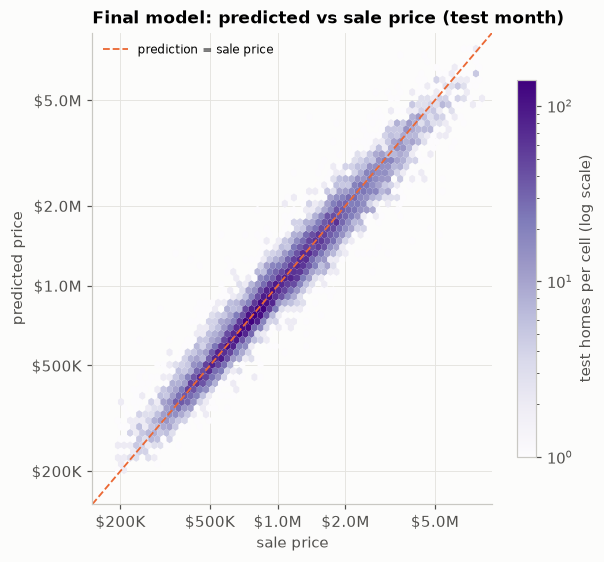

In [9]:
fig, ax = plt.subplots(figsize=(5.6, 5.2))
hb = ax.hexbin(y24 / 1e6, test_preds['LightGBM'] / 1e6, gridsize=60, xscale='log', yscale='log', bins='log',
               cmap='Purples', mincnt=1, linewidths=0)
lims = [0.15, 9]
ax.plot(lims, lims, color='#eb6834', lw=1.2, ls='--', label='prediction = sale price')
ax.set_xlim(lims); ax.set_ylim(lims)
ticks = [0.2, 0.5, 1, 2, 5]
ax.set_xticks(ticks, [money(t * 1e6) for t in ticks]); ax.set_yticks(ticks, [money(t * 1e6) for t in ticks])
ax.minorticks_off()
ax.set_xlabel('sale price'); ax.set_ylabel('predicted price')
ax.set_title('Final model: predicted vs sale price (test month)')
ax.legend(frameon=False, fontsize=8, loc='upper left')
fig.colorbar(hb, ax=ax, label='test homes per cell (log scale)', shrink=0.8)
plt.tight_layout()
save_fig('07_predicted_vs_actual')
plt.show()

## 5. By price band

The test homes are split into five groups of nearly equal size (Q1 cheapest, Q5 most expensive) in two ways:
- **By sale price.** This is what the task asks for, and how earlier weeks reported bands.
- **By predicted price.** This is the view of someone using the model: they see only the prediction, not the eventual sale price.

The two views answer different questions and need not agree. A home that sold for an unusually high price for what it is will usually be predicted lower, and it lands in a high sale-price band, so grouping by sale price makes the top band look underpriced (and the bottom band overpriced) even for a model with no bias overall. Grouping by prediction removes this effect.

In [10]:
pred_gb = test_preds['LightGBM'].to_numpy()
LABELS = [f'Q{i}' for i in range(1, 6)]
band_actual = pd.qcut(y_test, 5, labels=LABELS)
band_pred = pd.qcut(pred_gb, 5, labels=LABELS)


def band_table(bands, ref):
    t = mdl.segment_metrics(y_test, pred_gb, bands).reindex(LABELS)
    edges = pd.Series(ref).groupby(bands, observed=True).agg(['min', 'max']).reindex(LABELS)
    t.insert(0, 'range', [f'{money(a)} to {money(b)}' for a, b in edges.to_numpy()])
    return t


by_sale = band_table(band_actual, y_test)
by_pred = band_table(band_pred, pred_gb)
print('By sale price band:')
display(show(by_sale))
print('By predicted price band:')
show(by_pred)

By sale price band:


,range,homes,MAPE,MdAPE,within 10%,median signed error
group,,,,,,
Q1,$195K to $575K,"2,466",10.76%,6.31%,66.30%,0.90%
Q2,$575K to $800K,"2,481",7.98%,5.50%,74.45%,-0.60%
Q3,$802K to $1.1M,"2,403",8.66%,6.24%,70.58%,-0.96%
Q4,$1.1M to $1.7M,"2,448",10.47%,8.09%,59.52%,-2.65%
Q5,$1.7M to $8.1M,"2,450",12.72%,9.91%,50.12%,-4.51%


By predicted price band:


,range,homes,MAPE,MdAPE,within 10%,median signed error
group,,,,,,
Q1,$202K to $579K,"2,450",9.31%,6.31%,67.67%,-1.36%
Q2,$579K to $796K,"2,449",7.91%,5.45%,75.79%,-1.47%
Q3,$796K to $1.1M,"2,450",9.14%,6.54%,67.43%,-0.90%
Q4,$1.1M to $1.6M,"2,449",11.23%,8.31%,58.19%,-1.22%
Q5,$1.6M to $7.8M,"2,450",13.02%,9.49%,51.92%,-1.01%


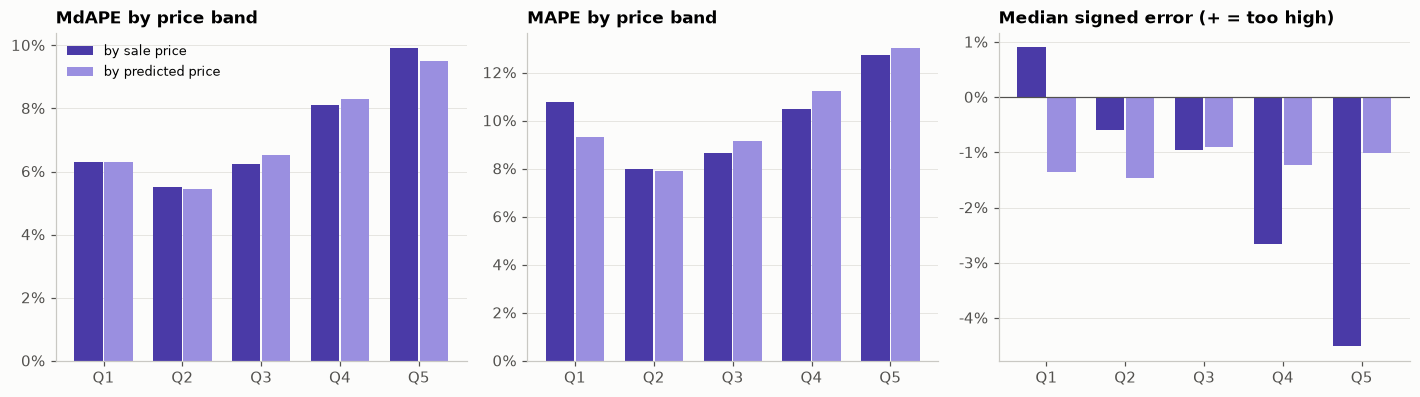

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
x = np.arange(5)
for k, (t, label, color) in enumerate([(by_sale, 'by sale price', COLORS['LightGBM']),
                                        (by_pred, 'by predicted price', '#9a8fe0')]):
    axes[0].bar(x + (k - 0.5) * 0.38, t['MdAPE'], width=0.36, color=color, label=label)
    axes[1].bar(x + (k - 0.5) * 0.38, t['MAPE'], width=0.36, color=color, label=label)
    axes[2].bar(x + (k - 0.5) * 0.38, t['median signed error'], width=0.36, color=color, label=label)
for ax, title in zip(axes, ['MdAPE by price band', 'MAPE by price band', 'Median signed error (+ = too high)']):
    ax.set_xticks(x, LABELS)
    ax.set_title(title)
    ax.grid(axis='x', visible=False)
    pct_axis(ax, 0)
axes[2].axhline(0, color='#52514e', lw=0.8)
axes[0].legend(frameon=False, fontsize=8.5)
plt.tight_layout()
save_fig('07_error_by_band')
plt.show()

**Progress by band since Week 4.** MdAPE by sale-price band for four models, on the 12,248 test homes they all scored (bands as above).

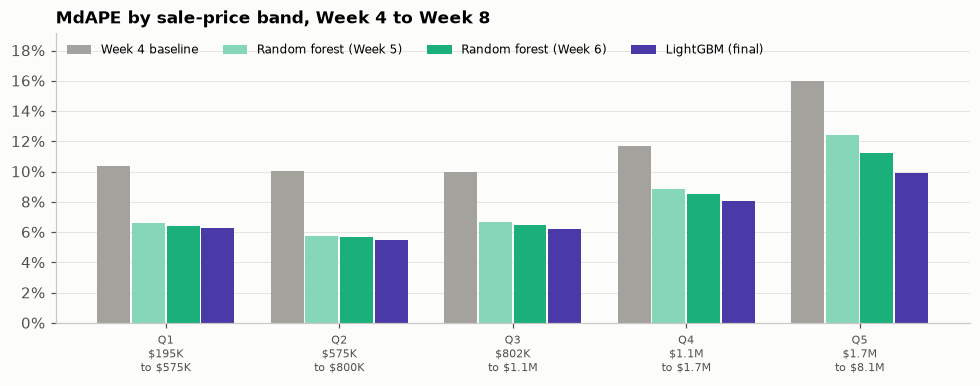

,Week 4 baseline,Random forest (Week 5),Random forest (Week 6),LightGBM (final)
group,,,,
Q1,10.35,6.63,6.43,6.31
Q2,10.05,5.76,5.69,5.50
Q3,9.97,6.67,6.46,6.24
Q4,11.72,8.84,8.53,8.09
Q5,15.99,12.42,11.22,9.91


In [12]:
band_common = pd.Series(band_actual, index=y24.index)
progress = pd.DataFrame({label: mdl.segment_metrics(y24, test_preds[key].loc[common], band_common)['MdAPE'].reindex(LABELS)
                         for key, label in [('Week 4 baseline', 'Week 4 baseline'), ('Random forest (Week 5)', 'Random forest (Week 5)'),
                                            ('Random forest', 'Random forest (Week 6)'), ('LightGBM', 'LightGBM (final)')]})
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [COLORS['Baseline'], COLORS['Random forest (Week 5)'], COLORS['Random forest'], COLORS['LightGBM']]
w = 0.2
for k, (col, c) in enumerate(zip(progress.columns, colors)):
    ax.bar(x + (k - 1.5) * w, progress[col], width=w * 0.95, color=c, label=col)
ax.set_xticks(x, [f'{q}\n{r}'.replace('$', r'\$').replace(' to ', '\nto ') for q, r in zip(LABELS, by_sale['range'])], fontsize=7.5)
pct_axis(ax, 0)
ax.yaxis.set_major_locator(mtick.MultipleLocator(2))
ax.grid(axis='x', visible=False)
ax.legend(frameon=False, fontsize=8, ncol=4, loc='upper left')
ax.set_ylim(0, progress.to_numpy().max() * 1.2)
ax.set_title('MdAPE by sale-price band, Week 4 to Week 8')
plt.tight_layout()
save_fig('07_band_progress')
plt.show()
progress.round(2)

## 6. By county

Counties with at least 100 test homes are shown separately; the rest are grouped. The price level of each county is the median sale price of its test homes.

In [13]:
MIN_HOMES = 100
county_counts = test_final['CountyOrParish'].value_counts()
big = county_counts[county_counts >= MIN_HOMES].index
other_label = f'Other counties ({(county_counts < MIN_HOMES).sum()})'
county = np.where(test_final['CountyOrParish'].isin(big), test_final['CountyOrParish'], other_label)
by_county = mdl.segment_metrics(y_test, pred_gb, county)
by_county.insert(1, 'median sale price', pd.Series(y_test).groupby(county).median())
by_county = by_county.sort_values('MdAPE')
view = show(by_county)
view['median sale price'] = by_county['median sale price'].map(money)
view

,homes,median sale price,MAPE,MdAPE,within 10%,median signed error
group,,,,,,
Riverside,"1,880",$639K,8.84%,5.53%,71.28%,-1.15%
Butte,144,$434K,7.82%,5.75%,68.06%,-0.76%
San Bernardino,"1,219",$559K,8.58%,5.95%,72.11%,-0.70%
San Luis Obispo,215,$945K,10.23%,6.23%,67.44%,-0.50%
Kern,134,$387K,10.14%,6.39%,67.16%,-2.32%
Ventura,419,$999K,10.37%,6.70%,62.29%,-1.51%
Orange,"1,165",$1.4M,8.92%,6.99%,65.84%,-1.73%
Contra Costa,583,$900K,9.69%,7.04%,64.15%,-1.26%
Other counties (36),745,$520K,11.02%,7.34%,61.88%,-1.68%


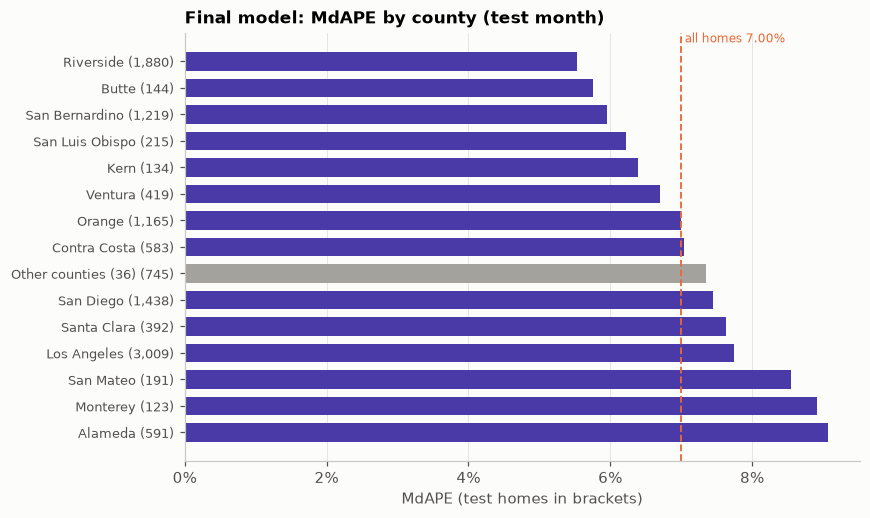

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.8))
t = by_county.iloc[::-1]
colors = ['#a3a29d' if i.startswith('Other') else COLORS['LightGBM'] for i in t.index]
ax.barh(range(len(t)), t['MdAPE'], color=colors, height=0.7)
overall = np.median(ape_gb)
ax.axvline(overall, color='#eb6834', lw=1.2, ls='--')
ax.text(overall, len(t) - 0.4, f' all homes {overall:.2f}%', color='#eb6834', fontsize=8, va='bottom')
ax.set_yticks(range(len(t)), [f'{i} ({n:,})' for i, n in zip(t.index, t['homes'])], fontsize=8.5)
pct_axis(ax, 0, axis='x')
ax.set_xlabel('MdAPE (test homes in brackets)')
ax.grid(axis='y', visible=False)
ax.set_title('Final model: MdAPE by county (test month)')
plt.tight_layout()
save_fig('07_error_by_county')
plt.show()

## 7. By home size, age and ZIP-code sales history

Three more ways to split the test homes:
- **Living area,** in five groups of nearly equal size.
- **Age at sale,** in fixed ranges.
- **ZIP-code sales history:** how many sales the home's ZIP code had in the 24 training months. The ZIP code is the model's strongest input (Week 7), and its value is learned from those past sales, so few past sales should mean a less reliable estimate.

In [15]:
area = test_final['LivingArea'].to_numpy()
area_bins = pd.qcut(area, 5)
area_labels = [f'{int(round(i.left, -1)):,} to {int(round(i.right, -1)):,}' for i in area_bins.categories]
area_group = pd.Categorical.from_codes(area_bins.codes, area_labels, ordered=True)

age = test_final['AgeAtSale'].to_numpy()
age_edges = [-np.inf, 5, 20, 40, 60, 80, np.inf]
age_labels = ['0 to 5', '6 to 20', '21 to 40', '41 to 60', '61 to 80', 'over 80']
age_group = pd.cut(age, age_edges, labels=age_labels)

zip_sales = train_final['ZIP5'].value_counts()
zip_n = test_final['ZIP5'].map(zip_sales).fillna(0).to_numpy()
zip_edges = [-1, 24, 49, 99, 199, 399, np.inf]
zip_labels = ['under 25', '25 to 49', '50 to 99', '100 to 199', '200 to 399', '400 or more']
zip_group = pd.cut(zip_n, zip_edges, labels=zip_labels)

segments = {
    'Living area (sq ft)': (area_group, area_labels),
    'Age at sale (years)': (age_group, age_labels),
    'Training sales in the ZIP code': (zip_group, zip_labels),
}
seg_tables = {}
for name, (groups, labels) in segments.items():
    t = mdl.segment_metrics(y_test, pred_gb, groups).reindex(labels)
    seg_tables[name] = t
    print(name)
    display(show(t))

Living area (sq ft)


,homes,MAPE,MdAPE,within 10%,median signed error
group,,,,,
"320 to 1,310","2,451",10.54%,7.29%,63.44%,-1.89%
"1,310 to 1,650","2,466",9.11%,6.41%,67.56%,-1.33%
"1,650 to 2,040","2,433",9.23%,6.40%,67.57%,-0.92%
"2,040 to 2,650","2,448",9.89%,6.88%,64.62%,-1.06%
"2,650 to 14,160","2,450",11.83%,8.21%,57.80%,-0.90%


Age at sale (years)


,homes,MAPE,MdAPE,within 10%,median signed error
group,,,,,
0 to 5,736,6.45%,4.29%,82.07%,-0.62%
6 to 20,"1,075",8.32%,5.31%,74.51%,-0.46%
21 to 40,"3,114",8.71%,6.06%,70.68%,-1.02%
41 to 60,"2,525",10.59%,7.58%,60.75%,-1.49%
61 to 80,"3,437",10.72%,7.90%,60.11%,-1.85%
over 80,"1,355",14.38%,10.38%,48.27%,-1.38%


Training sales in the ZIP code


,homes,MAPE,MdAPE,within 10%,median signed error
group,,,,,
under 25,183,14.94%,12.48%,44.26%,-3.27%
25 to 49,188,11.54%,8.17%,58.51%,-2.92%
50 to 99,377,11.28%,7.89%,59.95%,-0.52%
100 to 199,"1,644",11.45%,8.10%,58.76%,-1.98%
200 to 399,"3,412",10.92%,7.70%,60.02%,-1.45%
400 or more,"6,444",9.11%,6.24%,68.78%,-0.94%


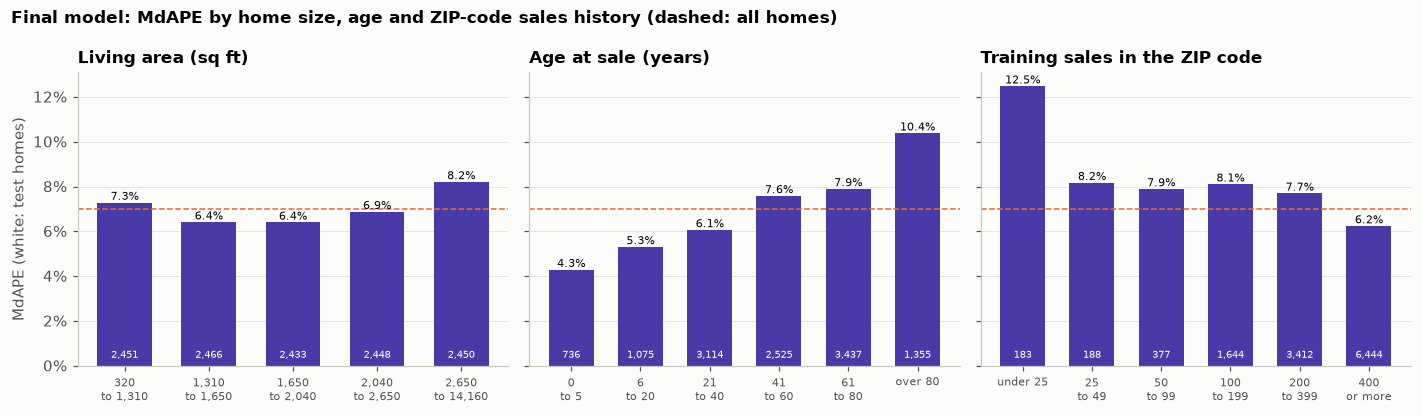

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (name, t) in zip(axes, seg_tables.items()):
    xs = np.arange(len(t))
    ax.bar(xs, t['MdAPE'], color=COLORS['LightGBM'], width=0.65)
    for i, (v, n) in enumerate(zip(t['MdAPE'], t['homes'])):
        ax.text(i, v, f'{v:.1f}%', ha='center', va='bottom', fontsize=7.5)
        ax.text(i, 0.25, f'{n:,}', ha='center', va='bottom', fontsize=6.5, color='white')
    ax.set_xticks(xs, [l.replace(' to ', '\nto ').replace(' or ', '\nor ') for l in t.index], fontsize=7.5)
    ax.set_title(name)
    ax.grid(axis='x', visible=False)
    ax.axhline(np.median(ape_gb), color='#eb6834', lw=1, ls='--')
pct_axis(axes[0], 0)
axes[0].set_ylabel('MdAPE (white: test homes)')
fig.suptitle('Final model: MdAPE by home size, age and ZIP-code sales history (dashed: all homes)', x=0.01, ha='left',
             fontsize=11, fontweight='bold')
plt.tight_layout()
save_fig('07_error_by_segment')
plt.show()

## 8. The largest misses

The 5% of test homes with the largest percentage errors are compared with the other 95%. Only group summaries are shown, no individual homes.

In [17]:
cut = np.percentile(ape_gb, 95)
worst = ape_gb > cut
signed_gb = (pred_gb - y_test) / y_test
tf = test_final.reset_index(drop=True)


def profile(mask):
    g = tf[mask]
    return {
        'homes': int(mask.sum()),
        'median percentage error (%)': np.median(ape_gb[mask]),
        'priced too high (%)': 100 * np.mean(signed_gb[mask] > 0),
        'median sale price': np.median(y_test[mask]),
        'median predicted price': np.median(pred_gb[mask]),
        'median living area (sq ft)': g['LivingArea'].median(),
        'median lot size (sq ft)': g['LotSizeSquareFeet'].median(),
        'median age (years)': g['AgeAtSale'].median(),
        'new construction (%)': 100 * g['NewConstructionYN'].mean(),
        'view (%)': 100 * g['ViewYN'].mean(),
        'pool (%)': 100 * g['PoolPrivateYN'].mean(),
        'lot size missing (%)': 100 * g['LotSizeSquareFeet'].isna().mean(),
        'location missing (%)': 100 * g['Latitude'].isna().mean(),
        'ZIP code with under 50 training sales (%)': 100 * np.mean(zip_n[mask] < 50),
        'median price per sq ft': np.median(y_test[mask] / g['LivingArea'].to_numpy()),
    }


worst_profile = pd.DataFrame({'largest 5% of errors': profile(worst), 'other 95%': profile(~worst)})
print(f'Largest misses: percentage error above {cut:.1f}%')
view = worst_profile.copy().astype(object)
for r in view.index:
    if r in ('median sale price', 'median predicted price'):
        view.loc[r] = [money(v) for v in worst_profile.loc[r]]
    elif r == 'median price per sq ft':
        view.loc[r] = [f'${v:,.0f}' for v in worst_profile.loc[r]]
    elif r == 'homes':
        view.loc[r] = [f'{v:,.0f}' for v in worst_profile.loc[r]]
    else:
        view.loc[r] = [f'{v:,.1f}' for v in worst_profile.loc[r]]
view

Largest misses: percentage error above 29.7%


,largest 5% of errors,other 95%
homes,613,"11,635"
median percentage error (%),37.8,6.6
priced too high (%),74.7,43.6
median sale price,$906K,$915K
median predicted price,$1.1M,$912K
median living area (sq ft),"1,908.0","1,828.0"
median lot size (sq ft),"8,993.5","7,201.0"
median age (years),61.0,49.0
new construction (%),0.5,3.2
view (%),70.6,62.0


In [18]:
county_share = pd.DataFrame({
    'share of largest misses (%)': 100 * tf.loc[worst, 'CountyOrParish'].value_counts(normalize=True),
    'share of all test homes (%)': 100 * tf['CountyOrParish'].value_counts(normalize=True),
}).fillna(0)
county_share['ratio'] = county_share.iloc[:, 0] / county_share.iloc[:, 1]
county_share.sort_values('share of largest misses (%)', ascending=False).head(8).round(2)

,share of largest misses (%),share of all test homes (%),ratio
CountyOrParish,,,
Los Angeles,25.77,24.57,1.05
Riverside,13.38,15.35,0.87
San Diego,11.58,11.74,0.99
Alameda,9.14,4.83,1.89
San Bernardino,8.32,9.95,0.84
Contra Costa,4.24,4.76,0.89
Ventura,4.24,3.42,1.24
Orange,3.92,9.51,0.41


## 9. Stability over time

The best-practices document asks for the same measures at several cutoffs, since one test month can be lucky or unlucky. Week 7 ran LightGBM (with the Week 7 setting) and the random forest on every month of 2025 and on the test month, each trained on the 12 months before it (a 24-month window cannot be trained before January 2026). Those results are summarized here from `results/06_stability_2025.csv`.

In [19]:
stab = pd.read_csv(RESULTS_DIR / '06_stability_2025.csv', dtype={'eval_month': str})
stab_summary = stab.groupby('model').agg(
    months=('eval_month', 'size'),
    **{'MdAPE lowest': ('MdAPE', 'min'), 'MdAPE highest': ('MdAPE', 'max'), 'MdAPE mean': ('MdAPE', 'mean'),
       'R2 lowest': ('R2', 'min'), 'R2 highest': ('R2', 'max'), 'MAPE mean': ('MAPE', 'mean')}
).loc[['Random forest', 'LightGBM']]
stab_summary.round(3)

,months,MdAPE lowest,MdAPE highest,MdAPE mean,R2 lowest,R2 highest,MAPE mean
model,,,,,,,
Random forest,13,7.14,7.67,7.44,0.89,0.91,10.91
LightGBM,13,6.80,7.25,7.09,0.91,0.93,10.34


## 10. Saved results

Scores go to `results/` (no property data; county groups with fewer than 100 test homes are combined), and the final model's settings to `config/model_config_week8.json`.
- `metrics_summary.csv`: all measures for every model (the Week 8 deliverable).
- `07_final_model_intervals.csv`: 95% ranges for the final model's measures.
- `07_error_by_segment.csv`: the final model's errors by price band, county, living area, age and ZIP-code sales history.
- `07_largest_misses.csv`: the summary comparison of the largest 5% of errors with the rest.
- `07_gb_extension.csv`: the extended tuning grid.

In [20]:
summary.reset_index().assign(test_month=TEST_MONTH).to_csv(RESULTS_DIR / 'metrics_summary.csv', index=False, float_format='%.6f')
intervals.reset_index(names='measure').to_csv(RESULTS_DIR / '07_final_model_intervals.csv', index=False, float_format='%.6f')

parts = [by_sale.drop(columns='range').assign(breakdown='Sale price band', range=by_sale['range']),
         by_pred.drop(columns='range').assign(breakdown='Predicted price band', range=by_pred['range']),
         by_county.drop(columns='median sale price').assign(breakdown='County')]
parts += [t.assign(breakdown=name) for name, t in seg_tables.items()]
segments_out = pd.concat([p.reset_index(names='group') for p in parts], ignore_index=True)
segments_out = segments_out[['breakdown', 'group', 'range', 'homes', 'MAPE', 'MdAPE', 'within 10%', 'median signed error']]
segments_out.to_csv(RESULTS_DIR / '07_error_by_segment.csv', index=False, float_format='%.6f')
worst_profile.reset_index(names='measure').to_csv(RESULTS_DIR / '07_largest_misses.csv', index=False, float_format='%.6f')
ext_table.reset_index().assign(learning_rate=lambda d: [k[0] for k in d['setting']],
                               max_depth=lambda d: [k[1] for k in d['setting']],
                               n_estimators=lambda d: [k[2] for k in d['setting']]).drop(columns='setting').to_csv(
    RESULTS_DIR / '07_gb_extension.csv', index=False, float_format='%.6f')

config = {
    'random_seed': SEED,
    'final_model': 'LightGBM on log(ClosePrice)',
    'inputs': FULL,
    'nearby_k': NEARBY_K,
    'n_train_months': N_MONTHS,
    'lightgbm': {**GB_FINAL, 'num_leaves': 2 ** GB_FINAL['max_depth'] - 1, 'min_child_samples': 20,
                 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'deterministic': True, 'n_jobs': 8},
    'grid_extension': {'learning_rate': EXT_RATE, 'depths': EXT_DEPTHS, 'tree_counts': EXT_COUNTS,
                       'changed_from_week7': FINAL_KEY != week7_key},
    'test_month': TEST_MONTH,
    'test_metrics': {k: summary.loc['Week 7/8: LightGBM (final)', k] for k in
                     ['homes', 'R2', 'MAE', 'RMSE', 'MAPE', 'MdAPE', 'within 5%', 'within 10%', 'within 20%']},
}
(ROOT / 'config' / 'model_config_week8.json').write_text(
    json.dumps(config, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o)))
print('Saved results and config/model_config_week8.json')

Saved results and config/model_config_week8.json


## 11. Summary and next steps

**Grid check.** Extending the Week 7 grid (learning rate 0.05, depths 8 to 10, up to 5,000 trees) gives a lowest validation MdAPE of 6.93% (depth 10, 3,000 trees), 0.04 points below the Week 7 setting with a standard error of 0.06 points for that gap. The one-standard-error rule keeps the Week 7 setting: **learning rate 0.05, depth 8, 3,000 trees.** The final model is unchanged.

**Test month (April 2026), all models** (`results/metrics_summary.csv`):

| Model | Inputs, months | R² | MAE | RMSE | MAPE | MdAPE | Within 10% | Within 20% |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| Week 4 baseline: linear regression | original, 12 | 0.820 | $207,051 | $408,669 | 15.17% | 11.38% | 44.7% | 74.5% |
| Week 5: random forest | original, 12 | 0.885 | $159,355 | $325,799 | 11.42% | 7.76% | 59.8% | 84.0% |
| Linear regression | new, 24 | 0.867 | $175,061 | $347,560 | 13.10% | 9.46% | 52.0% | 80.9% |
| Week 6: random forest | new, 24 | 0.900 | $148,862 | $300,880 | 10.81% | 7.40% | 61.4% | 86.2% |
| **LightGBM (final)** | **new, 24** | **0.920** | **$136,276** | **$269,320** | **10.12%** | **7.00%** | **64.2%** | **88.1%** |

Final model 95% ranges (1,000 resamples of the test homes): MdAPE 6.86% to 7.13%, MAPE 9.91% to 10.34%, R² 0.913 to 0.927.

**Error distribution.** The worst 5% of homes account for 22% of the total percentage error; dropping the worst 1% lowers MAPE from 10.12% to 9.45%. This skew is why MAPE exceeds MdAPE and why MdAPE is the headline.

**Where the model does well and where it does not (MdAPE):**
- Price band: best for $575K to $800K (5.5%), hardest for the top fifth (9.5% to 9.9%). Grouped by sale price the top fifth looks 4.5% underpriced, but grouped by predicted price every band is 0.9% to 1.5% low: most of the apparent top-band bias comes from grouping by the sale price.
- County: best Riverside (5.5%), Butte (5.8%), San Bernardino (6.0%); worst Alameda (9.1%), Monterey (8.9%), San Mateo (8.6%).
- Age: 4.3% for homes up to 5 years old, 10.4% for homes over 80.
- ZIP-code sales history: 12.5% with under 25 training sales in the ZIP code, 6.2% with 400 or more.
- Largest misses (top 5% of errors, above 29.7%): 75% priced too high; lower price per sq ft ($479 against $545) and older (61 against 49 years) than other homes, consistent with condition, which the inputs do not record.

**Stability.** Over the 13 months checked in Week 7 (12-month window), LightGBM's MdAPE stays between 6.80% and 7.25%. The signed error is negative in spring (February to April 2025: −2.3%, −1.8%, −1.2%; April 2026: −1.2%), when prices rise; the model lags rising prices.

**Next steps**
1. Week 9 (optional): a Streamlit app. The final model needs location, so the app should ask for a ZIP code or address besides living area, bedrooms, bathrooms and lot size, and fill the remaining inputs with typical values for that area.
2. Possible improvements: adjust for the most recent price trend; borrow neighboring ZIP codes' price levels for ZIP codes with few sales.